# Figure S9: training-cohort size

One row per task (healthy vs BRCA+CRC; healthy vs PANCAN):
- left: mean ROC over the outer test folds for each training-cohort size;
- middle: AUROC against cohort size (mean ± sd over outer folds, every fold as a point; a gray band
  spans the mean AUROC across subsample seeds where replicate runs exist);
- right: sensitivity and achieved specificity at the train-derived 95%-specificity threshold.

The full nested procedure is re-run per cohort size on nested stratified subsets (each smaller
subset is a strict subset of the larger one). Sizes from 20% of the cohort are shown.

Source data, written by `export/export_figS9.py`:
- `data/figS9_predictions.csv`: per (task, fraction, sample) out-of-fold score, fold, label, threshold.
- `data/figS9_sweep.csv`: per (task, fraction) sample and fold counts, AUROC summaries, modal configuration.
- `data/figS9_fold_configs.csv`: per-fold winning configuration (QC section).
- `data/figS9_seed_replicates.csv`: AUROC summaries of the replicate-seed sweeps (may be empty).

Run top to bottom from `src/figures/`.

In [1]:
import os

# Data paths are relative to src/figures/; change there if the kernel started elsewhere.
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# Cohort: "no_deep" (default; without the 30 deep-sequenced healthy controls, data/no_deep/) or
# "all" (full cohort, data/). Set here or via FIG_COHORT. Missing files fall back to data/.
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.interpolate import interp1d
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, roc_curve, auc

TASK_LABELS = {"brca_crc": "Healthy vs BRCA + CRC", "pancan": "Healthy vs PANCAN"}


def fraction_color(frac):
    """Sequential viridis: dark = full cohort, light = smallest."""
    return cm.viridis(0.9 - 0.8 * float(frac))

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


In [2]:
pred = pd.read_csv(data_path("figS9_predictions.csv"))
sweep = pd.read_csv(data_path("figS9_sweep.csv")).sort_values(
    ["task", "sample_fraction"], ascending=[True, False])
# Smallest subset shown: 20% (the 10% BRCA/CRC subset allows only 8 outer folds).
MIN_FRACTION = 0.2
pred = pred[pred["sample_fraction"] >= MIN_FRACTION - 1e-9]
sweep = sweep[sweep["sample_fraction"] >= MIN_FRACTION - 1e-9]
assert (sweep["n_outer_folds"] == 10).all(), sweep[["task", "sample_fraction", "n_outer_folds"]]
TASKS = [t for t in TASK_LABELS if t in set(sweep["task"])]
print(f"tasks: {TASKS}")

# Report fractions missing from the export (unfinished folds are skipped by the exporter).
CANONICAL_FRACTIONS = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]
INCOMPLETE = False
for task in TASKS:
    have = sorted(sweep.loc[sweep["task"] == task, "sample_fraction"], reverse=True)
    missing = [f for f in CANONICAL_FRACTIONS if not np.isclose(have, f).any()]
    if missing:
        INCOMPLETE = True
        print(f"  {task}: INTERMEDIATE - missing fractions "
              f"{', '.join(f'{f:.0%}' for f in missing)} "
              f"(present: {', '.join(f'{f:.0%}' for f in have)})")
    else:
        print(f"  {task}: complete ({len(have)} fractions)")
if INCOMPLETE:
    print("\n!! Intermediate results - do not commit these CSVs or the exported "
          "figure. Rerun the sweep array + aggregate + exporter for the full curve.")

# Replicate subsample seeds at the small fractions (across-seed band; none -> no band).
REP_COLS = ["task", "subsample_seed", "sample_fraction", "n_samples",
            "n_outer_folds", "mean_test_auc", "std_test_auc",
            "oof_auc_pooled", "source_dir"]
try:
    REPS = pd.read_csv(data_path("figS9_seed_replicates.csv"))
except FileNotFoundError:
    REPS = pd.DataFrame(columns=REP_COLS)
REPS = REPS[REPS["sample_fraction"] >= MIN_FRACTION - 1e-9]
for task in TASKS:
    r = REPS[REPS["task"] == task]
    if len(r):
        print(f"  {task}: replicate subsample seeds "
              f"{sorted(r['subsample_seed'].unique())} at fractions "
              f"{', '.join(f'{f:.0%}' for f in sorted(r['sample_fraction'].unique(), reverse=True))}")
    else:
        print(f"  {task}: no subsample-seed replicates - across-seed band omitted")

display(sweep[["task", "sample_fraction", "n_samples", "n_outer_folds",
               "mean_test_auc", "std_test_auc", "oof_auc_pooled",
               "modal_feature", "modal_classifier"]])

tasks: ['brca_crc', 'pancan']
  brca_crc: complete (9 fractions)
  pancan: complete (9 fractions)
  brca_crc: replicate subsample seeds [np.int64(43), np.int64(44), np.int64(45)] at fractions 40%, 30%, 20%
  pancan: replicate subsample seeds [np.int64(43), np.int64(44), np.int64(45)] at fractions 40%, 30%, 20%


,task,sample_fraction,n_samples,n_outer_folds,mean_test_auc,std_test_auc,oof_auc_pooled,modal_feature,modal_classifier
0,brca_crc,1.0,244,10,0.965717,0.029094,0.959832,griffin_diff,Support Vector Machine
1,brca_crc,0.9,220,10,0.960655,0.053461,0.958615,griffin_diff,Support Vector Machine
2,brca_crc,0.8,195,10,0.947894,0.062042,0.945551,griffin_diff,Support Vector Machine
3,brca_crc,0.7,171,10,0.939697,0.060813,0.946894,griffin_diff,Support Vector Machine
4,brca_crc,0.6,146,10,0.931556,0.077929,0.924320,griffin_diff,Support Vector Machine
5,brca_crc,0.5,122,10,0.897917,0.097707,0.847866,griffin_diff,Multi-Layer Perceptron
6,brca_crc,0.4,98,10,0.749603,0.157460,0.770833,griffin_diff,Multi-Layer Perceptron
7,brca_crc,0.3,73,10,0.780000,0.183303,0.727041,griffin_diff,Multi-Layer Perceptron
8,brca_crc,0.2,49,10,0.666667,0.387298,0.676136,griffin_diff,Multi-Layer Perceptron
10,pancan,1.0,367,10,0.969495,0.015244,0.966989,griffin_diff,Logistic Regression


## Helpers

Per-fold ROC curves and operating-point metrics at each fold's train-derived 95%-specificity threshold.

In [3]:
def fold_rocs(df):
    out = []
    for _, g in df.groupby("fold"):
        fpr, tpr, _ = roc_curve(g["y_true"], g["score"])
        out.append((fpr, tpr, auc(fpr, tpr)))
    return out


def fold_aucs(df):
    """AUROC of every outer fold, in fold order."""
    return np.array([a for _, _, a in fold_rocs(df)])


def _within_fold_ranks(df):
    """Each fold's scores mapped to ranks in [0, 1].

    Raw pooled OOF AUROC is not usable in this sweep: the nested selection can
    pick a different classifier in different outer folds, and pooling raw
    scores across folds whose score scales differ depresses the AUROC exactly
    where that drift is largest. Ranking within fold removes the scale
    mismatch; the QC section quantifies what it changes.
    """
    return df.groupby("fold")["score"].transform(
        lambda v: (rankdata(v) - 1) / max(len(v) - 1, 1))


def pooled_auc_ci(df, n_boot=2000, seed=0):
    """Rank-normalised pooled AUROC + class-stratified bootstrap 95% CI."""
    y = df["y_true"].to_numpy()
    r = _within_fold_ranks(df).to_numpy()
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos), replace=True),
                              rng.choice(neg, len(neg), replace=True)])
        if 0 < y[idx].sum() < len(idx):
            draws.append(roc_auc_score(y[idx], r[idx]))
    lo, hi = np.percentile(draws, [2.5, 97.5])
    return roc_auc_score(y, r), lo, hi


def operating_point(df):
    """Per-fold sensitivity and achieved specificity at the fold threshold."""
    sens, spec = [], []
    for _, g in df.groupby("fold"):
        thr = g["threshold_95spec"].iloc[0]
        y = g["y_true"].to_numpy()
        yhat = (g["score"] >= thr).astype(int).to_numpy()
        tp = np.sum((y == 1) & (yhat == 1)); fn = np.sum((y == 1) & (yhat == 0))
        tn = np.sum((y == 0) & (yhat == 0)); fp = np.sum((y == 0) & (yhat == 1))
        if tp + fn:
            sens.append(tp / (tp + fn))
        if tn + fp:
            spec.append(tn / (tn + fp))
    return sens, spec

## Panel columns

In [4]:
def panel_roc(ax, task):
    base_fpr = np.linspace(0, 1, 101)
    for _, row in sweep[sweep["task"] == task].iterrows():
        frac, n = row["sample_fraction"], int(row["n_samples"])
        df = pred[(pred["task"] == task) & (pred["sample_fraction"] == frac)]
        tprs, aucs = [], []
        for fpr, tpr, a in fold_rocs(df):
            tprs.append(interp1d(fpr, tpr, kind="linear")(base_fpr))
            aucs.append(a)
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[0], mean_tpr[-1] = 0, 1
        ax.plot(base_fpr, mean_tpr, color=fraction_color(frac), linewidth=1.9,
                label=f"{frac:>4.0%}  (n = {n})  AUC = {np.mean(aucs):.3f}")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, linewidth=1.2)
    ax.axvline(x=0.05, color="dimgray", linestyle=":", linewidth=1.4, alpha=0.85, zorder=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate", fontsize=14)
    ax.set_ylabel("True Positive Rate", fontsize=14)
    ax.legend(loc="lower right", fontsize=8.2, frameon=True, title="training cohort",
              title_fontsize=8.6)
    ax.tick_params(labelsize=11)
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_linewidth(1.0); spine.set_color("black")


def panel_auc_vs_n(ax, task):
    sub = sweep[sweep["task"] == task].sort_values("n_samples")
    n = sub["n_samples"].to_numpy()
    mean, sd = sub["mean_test_auc"].to_numpy(), sub["std_test_auc"].to_numpy()

    # Every outer fold as its own point.
    med, fold_x, fold_y = [], [], []
    for _, row in sub.iterrows():
        a = fold_aucs(pred[(pred["task"] == task)
                           & (pred["sample_fraction"] == row["sample_fraction"])])
        med.append(np.median(a))
        fold_x.extend([row["n_samples"]] * len(a))
        fold_y.extend(a)
    ax.plot(fold_x, fold_y, "o", color="#0173B2", alpha=0.22, markersize=4.5,
            markeredgewidth=0, linestyle="none", zorder=2,
            label="individual outer folds")

    ax.fill_between(n, np.maximum(mean - sd, 0), np.minimum(mean + sd, 1),
                    color="#0173B2", alpha=0.18, zorder=2.5,
                    label="± sd over outer folds")
    ax.plot(n, mean, "-o", color="#0173B2", linewidth=2.0, markersize=5,
            zorder=4, label="mean outer-fold AUROC")

    # Envelope of the mean AUROC over the main and replicate subsample seeds (same subset sizes).
    rep = REPS[REPS["task"] == task]
    if len(rep):
        both = pd.concat([sub[["n_samples", "mean_test_auc"]],
                          rep[["n_samples", "mean_test_auc"]]])
        env = (both.groupby("n_samples")["mean_test_auc"]
               .agg(["min", "max", "count"]).reset_index().sort_values("n_samples"))
        env = env[env["count"] >= 2]
        n_seeds = rep["subsample_seed"].nunique() + 1
        ax.fill_between(env["n_samples"], env["min"], env["max"],
                        color="#555555", alpha=0.22, linewidth=0, zorder=1.5,
                        label=f"range over {n_seeds} subsample seeds")
        ax.plot(rep["n_samples"], rep["mean_test_auc"], "o", mfc="none",
                mec="#555555", mew=1.1, markersize=4, linestyle="none",
                alpha=0.9, label="replicate seeds (mean AUROC)")

    ax.axhline(0.5, color="k", linestyle=":", linewidth=1.0, alpha=0.5)
    for x, f in zip(n, sub["sample_fraction"]):
        ax.annotate(f"{f:.0%}", (x, 1.035), ha="center", fontsize=7.5, color="dimgray",
                    annotation_clip=False)
    # Full 0-1 range: single folds at the smallest sizes can reach 0.
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("training-cohort size (samples)", fontsize=14)
    ax.set_ylabel("AUROC", fontsize=14)
    ax.legend(loc="lower right", fontsize=8.0)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=11)
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_linewidth(1.0); spine.set_color("black")


def panel_operating_point(ax, task):
    sub = sweep[sweep["task"] == task].sort_values("n_samples")
    rows = []
    for _, row in sub.iterrows():
        df = pred[(pred["task"] == task) & (pred["sample_fraction"] == row["sample_fraction"])]
        sens, spec = operating_point(df)
        rows.append({"n": int(row["n_samples"]),
                     "sens": np.mean(sens), "sens_sem": np.std(sens, ddof=1) / np.sqrt(len(sens))
                     if len(sens) > 1 else 0,
                     "spec": np.mean(spec), "spec_sem": np.std(spec, ddof=1) / np.sqrt(len(spec))
                     if len(spec) > 1 else 0})
    t = pd.DataFrame(rows)
    ax.errorbar(t["n"], t["sens"], yerr=t["sens_sem"], fmt="-o", color="#029E73",
                linewidth=2.0, markersize=5, capsize=3, label="sensitivity @ 95% spec.")
    ax.errorbar(t["n"], t["spec"], yerr=t["spec_sem"], fmt="--s", color="#6A3D9A",
                linewidth=1.6, markersize=4.5, capsize=3, label="achieved specificity")
    ax.axhline(0.95, color="k", linestyle=":", linewidth=1.0, alpha=0.5)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("training-cohort size (samples)", fontsize=14)
    ax.set_ylabel("Score at operating point", fontsize=14)
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=11)
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_linewidth(1.0); spine.set_color("black")

## Assemble Figure S9

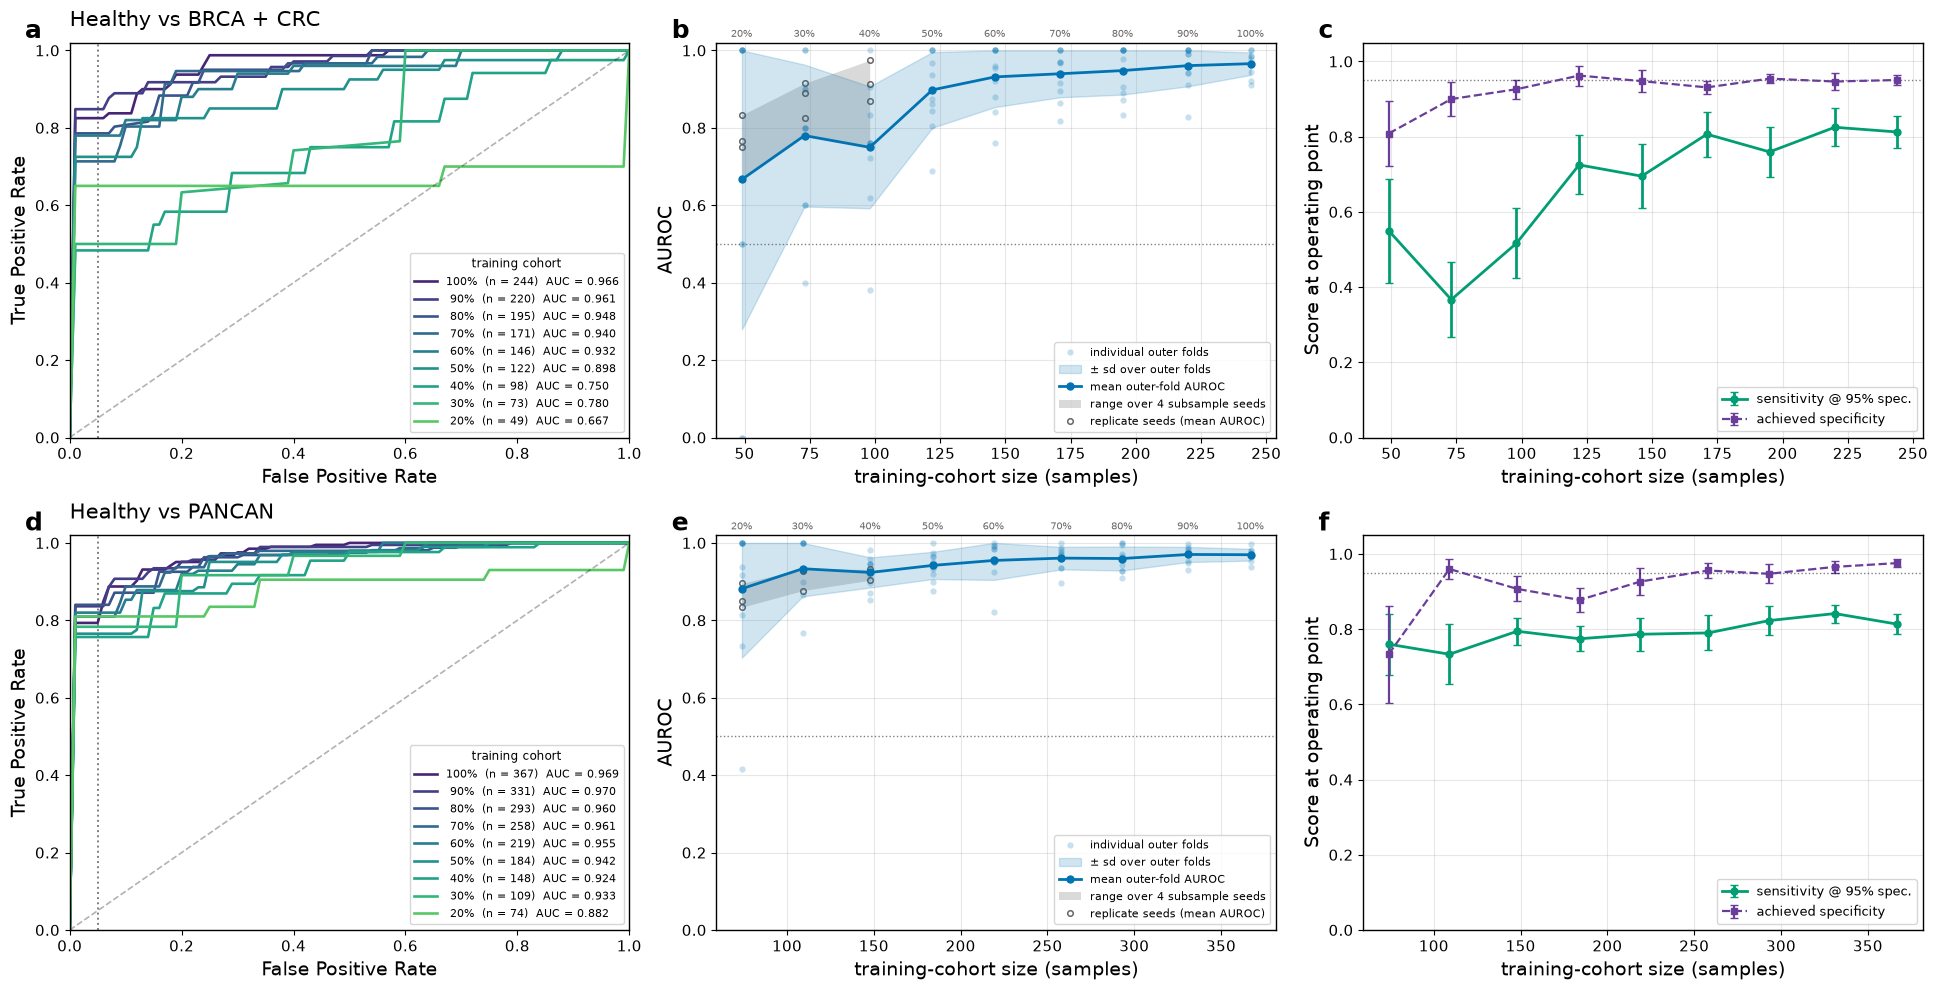

In [5]:
fig, axes = plt.subplots(len(TASKS), 3, figsize=(19.5, 5.0 * len(TASKS)), squeeze=False)
letters = iter("abcdef")
for i, task in enumerate(TASKS):
    panel_roc(axes[i][0], task)
    panel_auc_vs_n(axes[i][1], task)
    panel_operating_point(axes[i][2], task)
    axes[i][0].set_title(TASK_LABELS[task], fontsize=15, loc="left", pad=12)
    for ax in axes[i]:
        ax.text(-0.08, 1.06, next(letters), transform=ax.transAxes,
                fontsize=18, fontweight="bold", va="top")
plt.tight_layout()

os.makedirs("output", exist_ok=True)
fig.savefig(out_path("figS9.png"), dpi=300, bbox_inches="tight")
fig.savefig(out_path("figS9.pdf"), bbox_inches="tight")
plt.show()

## Summary numbers per cohort size

Smallest size within 0.02 of the full-cohort mean AUROC; smallest size whose bootstrap CI covers the
full-cohort AUROC; largest size from which every smaller size has a CI entirely below the full-cohort
CI; and the sizes at which the loss reaches 0.05 and 0.10. CIs are class-stratified bootstrap
percentile intervals over the pooled out-of-fold scores, rank-normalised within fold.

In [6]:
# ~2 s per task: bootstrap CI per cohort size on the rank-normalised pooled scores.
BOOT = 2000
CURVES = {}
for task in TASKS:
    rows = []
    for _, r in (sweep[sweep["task"] == task]
                 .sort_values("n_samples", ascending=False).iterrows()):
        df = pred[(pred["task"] == task)
                  & (pred["sample_fraction"] == r["sample_fraction"])]
        a, lo, hi = pooled_auc_ci(df, BOOT)
        rows.append({"frac": r["sample_fraction"], "n": int(r["n_samples"]),
                     "cases": int(df["y_true"].sum()),
                     "fold_mean": r["mean_test_auc"], "fold_sd": r["std_test_auc"],
                     "fold_med": float(np.median(fold_aucs(df))),
                     "auc": a, "lo": lo, "hi": hi, "ci_w": hi - lo})
    CURVES[task] = pd.DataFrame(rows)



for task in TASKS:
    t = CURVES[task].copy()
    full = t.iloc[0]
    ref = "full cohort" if np.isclose(full["frac"], 1.0) else \
        f"largest AVAILABLE cohort ({full['frac']:.0%} - 100% MISSING)"

    t["within_02"] = t["fold_mean"] >= full["fold_mean"] - 0.02
    t["indist"] = (t["lo"] <= full["auc"]) & (t["hi"] >= full["auc"])
    t["sig_below"] = t["hi"] < full["lo"]         # CI entirely below the full-cohort CI
    t["wide_ci"] = t["ci_w"] > 0.2

    print(f"=== {TASK_LABELS[task]} ===")
    print(f"  reference: {ref}, n = {int(full['n'])} "
          f"({int(full['cases'])} cancers), AUROC {full['fold_mean']:.3f} "
          f"+/- {full['fold_sd']:.3f} (CI {full['lo']:.3f}-{full['hi']:.3f})")
    t["loss"] = t["fold_mean"] - full["fold_mean"]
    print(t[["frac", "n", "cases", "fold_mean", "fold_sd", "fold_med", "loss",
             "auc", "lo", "hi", "ci_w", "within_02", "indist", "sig_below"]]
          .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

    for name, col in [("within 0.02 of reference", "within_02"),
                      ("not distinguishable from reference", "indist")]:
        ok = t[t[col]]
        if not len(ok):
            print(f"  {name}: none")
            continue
        smallest = ok.iloc[-1]
        # Larger sizes that fail the same test are listed as exceptions.
        exc = t[(t["n"] > smallest["n"]) & ~t[col]]
        note = "" if not len(exc) else \
            "  [exception at n = " + ", ".join(str(int(v)) for v in exc["n"]) + "]"
        print(f"  {name}: n = {int(smallest['n'])} ({smallest['frac']:.0%}, "
              f"{int(smallest['cases'])} cancers), AUROC {smallest['fold_mean']:.3f}"
              f"{note}")

    def _tail(flag):
        """Largest size whose flag holds for it AND every smaller size.

        Rows run n-descending, so this walks up from the bottom of the table
        and stops at the first size that breaks the run. An isolated failure
        higher up the curve therefore cannot masquerade as the onset.
        """
        m = t[flag].to_numpy()
        k = len(m)
        while k > 0 and m[k - 1]:
            k -= 1
        return None if k == len(m) else t.iloc[k]

    onset = _tail("sig_below")
    if onset is not None:
        print(f"  significantly below reference at every n <= {int(onset['n'])} "
              f"({onset['frac']:.0%}, {int(onset['cases'])} cancers)")
        iso = t[(t["n"] > onset["n"]) & t["sig_below"]]
        if len(iso):
            print("    isolated size(s) also below, not part of that run: n = "
                  + ", ".join(f"{int(v['n'])} ({v['frac']:.0%})"
                              for _, v in iso.iterrows()))
    unres = _tail("wide_ci")
    if unres is not None:
        print(f"  CI wider than 0.2 (sweep no longer resolves anything) at every "
              f"n <= {int(unres['n'])}")

    # Subsample-draw variance at the minimal-n reading, where replicates exist.
    ok = t[t["within_02"]]
    if len(ok):
        rep = REPS[(REPS["task"] == task)
                   & np.isclose(REPS["sample_fraction"], ok.iloc[-1]["frac"])]
        if len(rep):
            v = np.append(rep["mean_test_auc"].to_numpy(), ok.iloc[-1]["fold_mean"])
            print(f"  across {len(v)} subsample seeds at that n: "
                  f"{v.min():.3f}-{v.max():.3f} (range {v.max() - v.min():.3f})")

    # Where the loss relative to the full cohort reaches 0.05 / 0.10 for every smaller size.
    drop = []
    for loss in (0.05, 0.10):
        t["_d"] = (full["fold_mean"] - t["fold_mean"]) >= loss
        hit = _tail("_d")
        drop.append("no size" if hit is None
                    else f"n <= {int(hit['n'])} ({hit['frac']:.0%})")
    print(f"  drop-off: loses 0.05 AUROC at {drop[0]}, 0.10 AUROC at {drop[1]}")
    print()

=== Healthy vs BRCA + CRC ===
  reference: full cohort, n = 244 (80 cancers), AUROC 0.966 +/- 0.029 (CI 0.943-0.984)
 frac   n  cases  fold_mean  fold_sd  fold_med   loss   auc    lo    hi  ci_w  within_02  indist  sig_below
1.000 244     80      0.966    0.029     0.973  0.000 0.966 0.943 0.984 0.040       True    True      False
0.900 220     72      0.961    0.053     0.991 -0.005 0.960 0.931 0.982 0.052       True    True      False
0.800 195     64      0.948    0.062     0.989 -0.018 0.950 0.917 0.976 0.059       True    True      False
0.700 171     56      0.940    0.061     0.968 -0.026 0.938 0.896 0.969 0.073      False    True      False
0.600 146     48      0.932    0.078     0.958 -0.034 0.928 0.875 0.968 0.093      False    True      False
0.500 122     40      0.898    0.098     0.906 -0.068 0.896 0.823 0.953 0.130      False   False      False
0.400  98     32      0.750    0.157     0.762 -0.216 0.748 0.635 0.852 0.216      False   False       True
0.300  73     24   

# QC

Not part of the figure: winning configuration per cohort size, class balance, pooled-AUROC check,
achieved specificity (should scatter around 0.95) and the across-seed spread.

In [7]:
fold_cfg = pd.read_csv(data_path("figS9_fold_configs.csv"))
for task in TASKS:
    sub = fold_cfg[fold_cfg["task"] == task]
    print(f"=== {TASK_LABELS[task]}: configuration votes per cohort size ===")
    votes = (sub.groupby(["sample_fraction", "feature", "classifier"]).size()
             .rename("folds").reset_index()
             .sort_values(["sample_fraction", "folds"], ascending=[False, False]))
    print(votes.to_string(index=False))
    print()

# Composition check: stratified subsets keep the case/control ratio.
print("class balance per cohort size (must be flat down every column):")
bal = []
for (task, frac), g in pred.groupby(["task", "sample_fraction"]):
    cases = int(g["y_true"].sum())
    bal.append({"task": task, "frac": frac, "n": len(g),
                "controls": len(g) - cases, "cases": cases,
                "pct_cases": 100 * cases / len(g)})
bal = pd.DataFrame(bal).sort_values(["task", "frac"], ascending=[True, False])
print(bal.to_string(index=False, float_format=lambda v: f"{v:.1f}"))
for task in TASKS:
    p = bal.loc[bal["task"] == task, "pct_cases"]
    print(f"  {task}: cases {p.min():.1f}-{p.max():.1f}% across all sizes "
          f"(spread {p.max() - p.min():.1f} points)")

# Per-stratum counts (total n and per-type n shrink together).
print("\nsamples per stratum (each type shrinks proportionally):")
for task in TASKS:
    g = pred[pred["task"] == task]
    tab = (g.groupby(["stratification_label", "sample_fraction"]).size()
           .unstack(fill_value=0).sort_index(axis=1, ascending=False))
    tab.columns = [f"{c:.0%}" for c in tab.columns]
    print(f"\n  {TASK_LABELS[task]}")
    print(tab.to_string())
    cancers = tab.drop(index="Healthy", errors="ignore")
    print("  median cancer-type size:  "
          + "  ".join(f"{c}={cancers[c].median():.0f}" for c in cancers.columns))

print()
# Raw pooled OOF AUROC mixes score scales of different per-fold classifiers; compare it with
# the rank-normalised version and the fold mean.
print("pooled OOF AUROC: raw (exported) vs rank-normalised within fold")
rows = []
for (task, frac), g in pred.groupby(["task", "sample_fraction"]):
    cfgs = sweep.loc[(sweep["task"] == task)
                     & np.isclose(sweep["sample_fraction"], frac),
                     "n_distinct_configs"]
    rows.append({"task": task, "frac": frac,
                 "raw": roc_auc_score(g["y_true"], g["score"]),
                 "rank_norm": roc_auc_score(g["y_true"], _within_fold_ranks(g)),
                 "fold_mean": float(np.mean(fold_aucs(g))),
                 "n_configs": int(cfgs.iloc[0]) if len(cfgs) else -1})
qc = pd.DataFrame(rows).sort_values(["task", "frac"], ascending=[True, False])
qc["raw_deficit"] = qc["fold_mean"] - qc["raw"]
qc["rn_deficit"] = qc["fold_mean"] - qc["rank_norm"]
print(qc.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nmax |fold_mean - raw|        = {qc['raw_deficit'].abs().max():.3f}")
print(f"max |fold_mean - rank_norm|  = {qc['rn_deficit'].abs().max():.3f}")

print("\nachieved test specificity, mean over folds (must scatter around 0.95):")
rows = []
for (task, frac), g in pred.groupby(["task", "sample_fraction"]):
    _, spec = operating_point(g)
    rows.append({"task": task, "fraction": frac, "mean_spec": np.mean(spec),
                 "n_folds": g["fold"].nunique()})
print(pd.DataFrame(rows).pivot(index="fraction", columns="task", values="mean_spec")
      .sort_index(ascending=False).to_string(float_format=lambda v: f"{v:.3f}"))

# Mean outer-fold AUROC per subsample seed (main seed 42 and replicates) and the range.
for task in TASKS:
    rep = REPS[REPS["task"] == task]
    if not len(rep):
        continue
    main = (sweep[sweep["task"] == task][["sample_fraction", "mean_test_auc"]]
            .assign(seed="main(42)"))
    r = (rep[["sample_fraction", "mean_test_auc"]]
         .assign(seed=rep["subsample_seed"].map(lambda s: f"seed{s}")))
    piv = (pd.concat([main, r])
           .pivot(index="sample_fraction", columns="seed", values="mean_test_auc")
           .sort_index(ascending=False))
    piv = piv[piv.drop(columns="main(42)").notna().any(axis=1)]
    piv["range"] = piv.max(axis=1) - piv.min(axis=1)
    print(f"\n=== {TASK_LABELS[task]}: mean outer-fold AUROC per subsample seed ===")
    print(piv.to_string(float_format=lambda v: f"{v:.3f}"))

=== Healthy vs BRCA + CRC: configuration votes per cohort size ===
 sample_fraction       feature             classifier  folds
             1.0  griffin_diff Support Vector Machine     10
             0.9  griffin_diff Support Vector Machine     10
             0.8  griffin_diff Support Vector Machine     10
             0.7  griffin_diff Support Vector Machine     10
             0.6  griffin_diff Support Vector Machine      7
             0.6  griffin_diff Multi-Layer Perceptron      3
             0.5  griffin_diff Multi-Layer Perceptron      6
             0.5  griffin_diff Support Vector Machine      4
             0.4  griffin_diff Multi-Layer Perceptron      5
             0.4  griffin_diff Support Vector Machine      2
             0.4          fslr                XGBoost      1
             0.4 fslr_coverage Multi-Layer Perceptron      1
             0.4  griffin_diff    K-Nearest Neighbors      1
             0.3  griffin_diff Multi-Layer Perceptron      7
             0.3  

    task  frac   raw  rank_norm  fold_mean  n_configs  raw_deficit  rn_deficit
brca_crc 1.000 0.960      0.966      0.966          3        0.006       0.000
brca_crc 0.900 0.959      0.960      0.961          3        0.002       0.001
brca_crc 0.800 0.946      0.950      0.948          3        0.002      -0.002
brca_crc 0.700 0.947      0.938      0.940          5       -0.007       0.002
brca_crc 0.600 0.924      0.928      0.932          7        0.007       0.003
brca_crc 0.500 0.848      0.896      0.898          5        0.050       0.002
brca_crc 0.400 0.771      0.748      0.750         10       -0.021       0.001
brca_crc 0.300 0.727      0.770      0.780         10        0.053       0.010
brca_crc 0.200 0.676      0.686      0.667          9       -0.009      -0.019
  pancan 1.000 0.967      0.969      0.969          3        0.003       0.000
  pancan 0.900 0.968      0.970      0.970          5        0.002       0.000
  pancan 0.800 0.962      0.959      0.960          